# Create residual character training data
Read existing Magi caches only. Reuse the original GT acceptance rules and sequence split.

Save only **training_data.pt**. Embeddings appear once in `sequences`; training uses triplet row indices and validation/test use pair row indices. GT IDs are local to each sequence; -1 means unaccepted. Predicted clusters never supply training identities.


## 1. Settings
Prefer all cross-page positive pairs. same-page pairs are used only for characters that have no accepted appearances across different pages. Generate one triplet per selected positive pair, without oversampling. A shared sequence cap (median eligible positive count, at most 4,000) limits large sequences while keeping small sequences intact.

Select 70% of negatives from the anchor's top 20 different-GT candidates by raw cosine; select the rest randomly. All negatives are accepted appearances in the same sequence. The hard/random flag records the sampling method; random selection may also pick a hard candidate.


In [1]:
import torch
import torch.nn.functional as F
import json, hashlib, random, unicodedata
from pathlib import Path
from collections import defaultdict, Counter
from itertools import combinations
from difflib import SequenceMatcher
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

ROOT = Path('C:/Users/ESHAAN/BYTE/Applied-Task/Magi/charSimResidual')
CACHE = ROOT.parent / 'paddleOCR-Magi' / 'cache_baseline' / 'development'
LABELS = ROOT.parent / 'TaskData' / 'development' / 'labels.jsonl'
DATA_FILE = ROOT / 'training_data.pt'
SEED = 42
MIN_SCORE = 95.0
MAX_TRIPLETS_PER_SEQUENCE = 4000
HARD_NEGATIVE_FRACTION = 0.7
HARD_NEGATIVE_TOP_K = 20
TRAIN_FRACTION, VAL_FRACTION = 0.70, 0.15

def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=True,
                                    allow_nan=False).encode()).hexdigest()

def read_cache(path):
    saved = json.loads(path.read_text(encoding='utf-8'))
    assert digest(saved['data']) == saved['data_hash'], f'Changed cache: {path.name}'
    assert digest(saved['settings']) == saved['signature'], f'Changed settings: {path.name}'
    return saved

def normalize(text):
    text = unicodedata.normalize('NFKC', text or '').casefold()
    words = ' '.join(''.join(c if c.isalnum() else ' ' for c in text).split())
    return words or ' '.join(''.join(c for c in text if c.isspace() or
                                    unicodedata.category(c)[0] in {'P', 'S'}).split())

def fuzzy(a, b):
    a, b = normalize(a), normalize(b)
    return 100 * SequenceMatcher(None, a, b, autojunk=False).ratio() if a and b else 0.0

with LABELS.open(encoding='utf-8') as file:
    labels = {entry['sequence_id']: entry for entry in
              (json.loads(line) for line in file if line.strip())}


## 2. Accept candidate identities
Require one distinct character link per bubble. Joined bubbles must all link to the same appearance. Reject competing ≥95% GT matches with different speakers. Consolidate repeated bubble evidence; exclude appearances with conflicting identities.

Cache checks bind OCR matches and embeddings to the same raw predictions and unchanged GT labels. Store minimal evidence references so accepted crops can be reviewed.


In [2]:
def read_sequence(folder):
    raw = read_cache(folder / 'magi_raw.json')
    match = read_cache(folder / 'gt_matches.json')
    embed = read_cache(folder / 'character_embeddings.json')
    gt = labels[folder.name]
    assert raw['settings']['sequence_id'] == gt['sequence_id'] == folder.name
    for saved in (match, embed):
        assert saved['settings']['magi_signature'] == raw['signature']
        assert saved['settings']['magi_data_hash'] == raw['data_hash']
    assert match['settings']['labels_sha256'] == digest(gt)
    assert embed['settings']['model'] == raw['settings']['model']
    assert embed['settings']['pages'] == raw['settings']['pages']
    assert embed['data']['normalization'] == 'none'
    assert embed['data']['embedding_dim'] == 768
    assert len(raw['data']) == len(embed['data']['pages']) == len(gt['pages'])

    vectors, boxes, pages, chars, clusters = [], [], [], [], []
    lookup, links = {}, defaultdict(set)
    for p, (page, embedded) in enumerate(zip(raw['data'], embed['data']['pages'])):
        assert embedded['page_index'] == p
        assert embedded['page_file'] == raw['settings']['pages'][p]['name']
        assert len(page['texts']) == len(page['ocr'])
        assert len(page['characters']) == len(embedded['characters']) == len(page['character_cluster_labels'])
        for c, record in enumerate(embedded['characters']):
            assert record['character_index'] == c and record['box'] == page['characters'][c]
            lookup[p, c] = len(vectors)
            vectors.append(record['embedding'])
            boxes.append(record['box'])
            pages.append(p); chars.append(c)
            clusters.append(int(page['character_cluster_labels'][c]))
        for t, c in page['text_character_associations']:
            assert 0 <= t < len(page['texts']) and 0 <= c < len(page['characters'])
            links[p, t].add(c)

    matrix = torch.tensor(vectors, dtype=torch.float32).reshape(-1, 768)
    assert matrix.shape == (len(vectors), 768) and torch.isfinite(matrix).all()
    evidence, rejected = defaultdict(list), Counter()
    for group in match['data']['groups']:
        if not (group['stage'] in {'direct', 'adjacent_join'} and
                group['scores']['full_ratio'] >= MIN_SCORE):
            continue
        p, indices = group['page_index'], group['text_indices']
        assert indices and len(indices) == len(set(indices))
        assert all(0 <= t < len(raw['data'][p]['texts']) for t in indices)
        assert (group['stage'] == 'direct' and len(indices) == 1) or (
            group['stage'] == 'adjacent_join' and len(indices) == 2 and indices[1] == indices[0] + 1)
        text = ' '.join(raw['data'][p]['ocr'][t] for t in indices)
        assert text == group['ocr_text']
        line = gt['pages'][p][group['gt_index']]
        assert line['text'] == group['gt_text'] and line['speaker'] == group['gt_speaker']
        speaker = line['speaker']
        candidates = {line['speaker'] for line in gt['pages'][p]
                      if fuzzy(text, line['text']) >= MIN_SCORE}
        if not isinstance(speaker, str) or not speaker.strip() or candidates != {speaker}:
            rejected['ambiguous_or_missing_GT'] += 1
            continue
        linked = [links[p, t] for t in indices]
        if any(len(s) != 1 for s in linked) or len(set.union(*linked)) != 1:
            rejected['missing_multiple_or_disagreeing_links'] += 1
            continue
        row = lookup[p, next(iter(linked[0]))]
        evidence[row].append(dict(speaker=speaker, text_indices=indices,
                                 gt_index=group['gt_index'], score=group['scores']['full_ratio']))

    names = sorted({line['speaker'] for page in gt['pages'] for line in page
                    if isinstance(line['speaker'], str) and line['speaker'].strip()})
    identity = torch.full((len(matrix),), -1, dtype=torch.long)
    accepted_evidence = {}
    for row, items in evidence.items():
        speakers = {item['speaker'] for item in items}
        if len(speakers) != 1:
            rejected['conflicting_appearance'] += 1
            continue
        identity[row] = names.index(next(iter(speakers)))
        accepted_evidence[str(row)] = items
    sequence = dict(id=folder.name, embeddings=matrix, gt=identity,
                    page=torch.tensor(pages, dtype=torch.long),
                    character=torch.tensor(chars, dtype=torch.long),
                    cluster=torch.tensor(clusters, dtype=torch.long),
                    boxes=torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4),
                    page_files=[p['name'] for p in raw['settings']['pages']],
                    speaker_names=names, evidence=accepted_evidence,
                    source_hashes=[raw['data_hash'], match['data_hash'], embed['data_hash']])
    return sequence, rejected, digest(embed['settings']['model'])

sequences, excluded, rejected_counts = [], [], Counter()
encoder = None
for folder in sorted(p.parent for p in CACHE.glob('*/magi_raw.json')):
    try:
        sequence, rejected, model_hash = read_sequence(folder)
        assert encoder is None or encoder == model_hash, 'Mixed Magi encoders'
        encoder = model_hash
        sequences.append(sequence)
        rejected_counts.update(rejected)
    except Exception as error:
        excluded.append((folder.name, str(error)))
print('Valid sequences:', len(sequences), '| excluded:', len(excluded))
print('Accepted appearances:', sum(int((s['gt'] >= 0).sum()) for s in sequences))
print('Rejected evidence:', dict(rejected_counts))
if excluded:
    display(pd.DataFrame(excluded, columns=['sequence', 'reason']))
assert len(sequences) >= 3, 'Need at least three valid sequences.'


Valid sequences: 80 | excluded: 0
Accepted appearances: 870
Rejected evidence: {'missing_multiple_or_disagreeing_links': 62, 'conflicting_appearance': 121, 'ambiguous_or_missing_GT': 8}


## 3. Review a few accepted crops
Read the original page crops and supporting bubble/GT references before trusting this supervision. This is a visual spot check, not automatic verification. No review images are saved.


seq_98d98dac2a89a339 appearance row 27 | evidence: [{'speaker': 'character6', 'text_indices': [12], 'gt_index': 12, 'score': 100.0}]
seq_aef69e98002294bc appearance row 1 | evidence: [{'speaker': 'character1', 'text_indices': [0], 'gt_index': 0, 'score': 100.0}, {'speaker': 'character1', 'text_indices': [2], 'gt_index': 2, 'score': 100.0}, {'speaker': 'character1', 'text_indices': [3], 'gt_index': 3, 'score': 100.0}, {'speaker': 'character1', 'text_indices': [7], 'gt_index': 5, 'score': 100.0}, {'speaker': 'character1', 'text_indices': [8], 'gt_index': 6, 'score': 100.0}]
seq_a3bd36201a0cd61b appearance row 19 | evidence: [{'speaker': 'NARRATION', 'text_indices': [10], 'gt_index': 6, 'score': 97.67441860465115}, {'speaker': 'NARRATION', 'text_indices': [11], 'gt_index': 7, 'score': 100.0}]
seq_7db7a000adeceacf appearance row 27 | evidence: [{'speaker': 'character1', 'text_indices': [4], 'gt_index': 3, 'score': 100.0}]
seq_b136f32c2233b97c appearance row 7 | evidence: [{'speaker': 'char

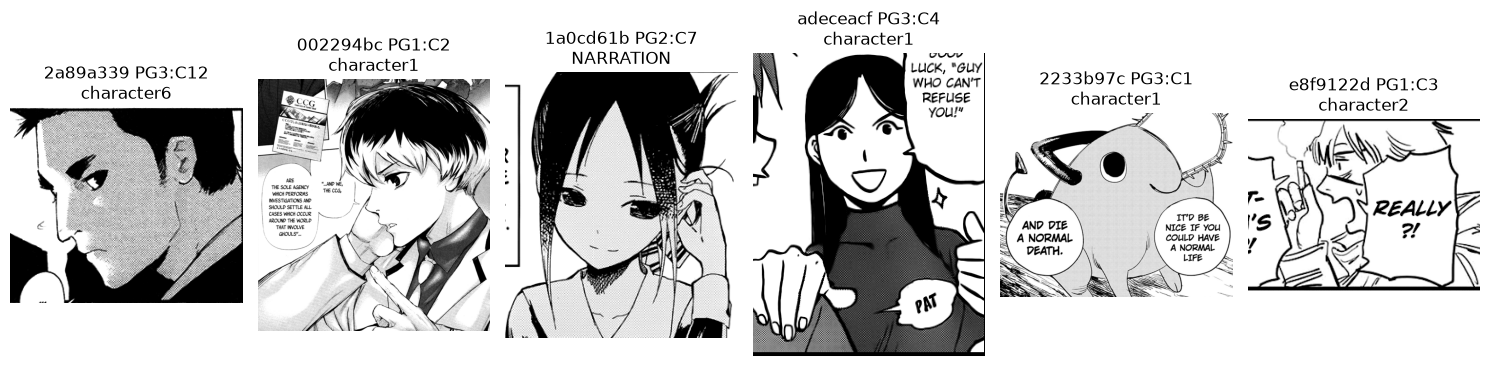

In [3]:
review = [(i, row) for i, s in enumerate(sequences) for row in range(len(s['gt']))
          if s['gt'][row] >= 0]
random.Random(SEED).shuffle(review)
if review:
    fig, axes = plt.subplots(1, min(6, len(review)), figsize=(15, 4), squeeze=False)
    for ax, (i, row) in zip(axes[0], review[:6]):
        s = sequences[i]
        p = int(s['page'][row])
        image_path = ROOT.parent / 'TaskData' / 'development' / 'images' / s['id'] / s['page_files'][p]
        with Image.open(image_path) as image:
            ax.imshow(image.crop(s['boxes'][row].tolist()).convert('RGB'))
        ax.set_title(f"{s['id'][-8:]} PG{p+1}:C{int(s['character'][row])+1}\n{s['speaker_names'][int(s['gt'][row])]}")
        ax.axis('off')
        print(s['id'], 'appearance row', row, '| evidence:', s['evidence'][str(row)])
    plt.tight_layout(); plt.show()


## 4. Split sequences and build samples
Keep the original seeded sequence split and all labeled validation/test pairs. Training identities require at least two appearances and another accepted identity for a negative.

Saved structure:
- `sequences`: original appearance tables. `embeddings[row]`, `gt[row]`, `page[row]`, and `character[row]` describe one appearance. Page/character indices are zero-based; displayed IDs are one-based.
- `splits`: sequence indices for train, validation, and test.
- `triplets`: `indices` columns are **sequence_idx, anchor_idx, positive_idx, negative_idx**; two raw similarity tensors and `is_hard_negative` have one entry per row.
- `pairs`: validation/test row columns are **sequence_idx, appearance_a_idx, appearance_b_idx, same_GT**.
- `settings`: seed, mining settings, cap, and encoder reference. `schema` documents row columns.

No per-triplet embeddings, extra datasets, or diagnostic files are saved.


In [4]:
rng = random.Random(SEED)
order = list(range(len(sequences)))
rng.shuffle(order)
n_train = min(max(1, int(len(order) * TRAIN_FRACTION)), len(order) - 2)
n_val = min(max(1, int(len(order) * VAL_FRACTION)), len(order) - n_train - 1)
splits = dict(train=order[:n_train], validation=order[n_train:n_train+n_val],
              test=order[n_train+n_val:])

def positive_pairs(sequence):
    accepted = torch.where(sequence['gt'] >= 0)[0].tolist()
    if len({int(sequence['gt'][row]) for row in accepted}) < 2:
        return []
    cross_page, same_page = [], []
    cross_identities = set()
    for a, p in combinations(accepted, 2):
        if sequence['gt'][a] != sequence['gt'][p]:
            continue
        if sequence['page'][a] != sequence['page'][p]:
            cross_page.append((a, p))
            cross_identities.add(int(sequence['gt'][a]))
        else:
            same_page.append((a, p))
    supplementary = [(a, p) for a, p in same_page
                     if int(sequence['gt'][a]) not in cross_identities]
    local = random.Random(f'{SEED}:{sequence["id"]}:positives')
    local.shuffle(cross_page)
    local.shuffle(supplementary)
    return cross_page + supplementary

positives = {i: positive_pairs(sequences[i]) for i in splits['train']}
counts = [len(rows) for rows in positives.values() if rows]
assert counts, 'No training sequence can form triplets.'
sequence_cap = min(MAX_TRIPLETS_PER_SEQUENCE, max(1, int(np.median(counts))))
triplet_rows, raw_positive, raw_negative, hard_flags = [], [], [], []
for i, positive in positives.items():
    sequence = sequences[i]
    selected = positive[:sequence_cap]
    local = random.Random(f'{SEED}:{sequence["id"]}:negatives')
    modes = [True] * round(len(selected) * HARD_NEGATIVE_FRACTION)
    modes += [False] * (len(selected) - len(modes))
    local.shuffle(modes)
    unit = F.normalize(sequence['embeddings'], dim=-1)
    accepted = torch.where(sequence['gt'] >= 0)[0].tolist()
    candidates_by_anchor = {}
    for (a, p), hard in zip(selected, modes):
        # Randomly orient each positive pair; never duplicate it in reverse.
        if local.random() < 0.5:
            a, p = p, a
        if a not in candidates_by_anchor:
            candidates = [n for n in accepted if sequence['gt'][n] != sequence['gt'][a]]
            ranked = sorted(candidates, key=lambda n: float(torch.dot(unit[a], unit[n])),
                            reverse=True)
            candidates_by_anchor[a] = (candidates, ranked[:HARD_NEGATIVE_TOP_K])
        candidates, top_k = candidates_by_anchor[a]
        n = local.choice(top_k if hard else candidates)
        assert a != p and sequence['gt'][a] == sequence['gt'][p]
        assert sequence['gt'][n] >= 0 and sequence['gt'][n] != sequence['gt'][a]
        triplet_rows.append([i, a, p, n])
        raw_positive.append(float(torch.dot(unit[a], unit[p])))
        raw_negative.append(float(torch.dot(unit[a], unit[n])))
        hard_flags.append(hard)

triplets = dict(indices=torch.tensor(triplet_rows, dtype=torch.long),
                raw_positive_similarity=torch.tensor(raw_positive),
                raw_negative_similarity=torch.tensor(raw_negative),
                is_hard_negative=torch.tensor(hard_flags, dtype=torch.bool))
pairs = {}
for split in ['validation', 'test']:
    rows = []
    for i in splits[split]:
        sequence = sequences[i]
        accepted = torch.where(sequence['gt'] >= 0)[0].tolist()
        rows.extend([i, a, b, int(sequence['gt'][a] == sequence['gt'][b])]
                    for a, b in combinations(accepted, 2))
    pairs[split] = torch.tensor(rows, dtype=torch.long).reshape(-1, 4)
    assert len(rows) and set(pairs[split][:, 3].tolist()) == {0, 1}, f'{split} needs both classes.'

cross_count = sum(int(sequences[i]['page'][a] != sequences[i]['page'][p])
                  for i, a, p, n in triplet_rows)
print('Train appearances (all / accepted):',
      sum(len(sequences[i]['gt']) for i in splits['train']), '/',
      sum(int((sequences[i]['gt'] >= 0).sum()) for i in splits['train']))
print('Train triplets:', len(triplet_rows))
print('Cross-page positive triplets:', cross_count)
print('Hard-negative triplets:', sum(hard_flags))
print('Random-negative triplets:', len(hard_flags) - sum(hard_flags))
print('Unique sequences contributing triplets:', len({row[0] for row in triplet_rows}))
print('Shared sequence cap:', sequence_cap)
display(pd.DataFrame([dict(split=split, sequences=len(splits[split]), pairs=len(rows))
                      for split, rows in pairs.items()]))

def appearance_id(sequence, row):
    return f"PG{int(sequence['page'][row])+1}:C{int(sequence['character'][row])+1}"

examples = []
for index, (i, a, p, n) in enumerate(triplet_rows[:5]):
    sequence = sequences[i]
    examples.append(dict(sequence=sequence['id'], anchor_idx=a, positive_idx=p, negative_idx=n,
                         anchor=appearance_id(sequence, a), positive=appearance_id(sequence, p),
                         negative=appearance_id(sequence, n),
                         positive_GT=sequence['speaker_names'][int(sequence['gt'][a])],
                         negative_GT=sequence['speaker_names'][int(sequence['gt'][n])],
                         raw_positive_similarity=raw_positive[index],
                         raw_negative_similarity=raw_negative[index], hard_negative=hard_flags[index]))
display(pd.DataFrame(examples).round(4))
dataset = dict(version=3, sequences=sequences, splits=splits, triplets=triplets, pairs=pairs,
               schema=dict(triplet_columns=['sequence_idx', 'anchor_idx', 'positive_idx', 'negative_idx'],
                           pair_columns=['sequence_idx', 'appearance_a_idx', 'appearance_b_idx', 'same_GT']),
               settings=dict(seed=SEED, min_score=MIN_SCORE, encoder=encoder,
                             hard_negative_fraction=HARD_NEGATIVE_FRACTION,
                             hard_negative_top_k=HARD_NEGATIVE_TOP_K,
                             max_triplets_per_sequence=MAX_TRIPLETS_PER_SEQUENCE,
                             effective_sequence_cap=sequence_cap))
torch.save(dataset, DATA_FILE)
print('Saved one dataset:', DATA_FILE)


Train appearances (all / accepted): 1418 / 579
Train triplets: 531
Cross-page positive triplets: 485
Hard-negative triplets: 379
Random-negative triplets: 152
Unique sequences contributing triplets: 51
Shared sequence cap: 14


,split,sequences,pairs
0,validation,12,693
1,test,12,1200


,sequence,anchor_idx,positive_idx,negative_idx,anchor,positive,negative,positive_GT,negative_GT,raw_positive_similarity,raw_negative_similarity,hard_negative
0,seq_b8b5563330fdc89d,30,5,17,PG2:C16,PG1:C6,PG2:C3,character2,character4,0.4122,0.4297,True
1,seq_b8b5563330fdc89d,17,40,27,PG2:C3,PG3:C9,PG2:C13,character4,character3,0.8859,0.6929,True
2,seq_b8b5563330fdc89d,10,33,17,PG1:C11,PG3:C2,PG2:C3,character2,character4,0.9490,0.3719,False
3,seq_b8b5563330fdc89d,14,37,9,PG1:C15,PG3:C6,PG1:C10,character3,character1,0.8571,0.8307,True
4,seq_b8b5563330fdc89d,10,21,24,PG1:C11,PG2:C7,PG2:C10,character2,character4,0.9547,0.4488,True


Saved one dataset: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\charSimResidual\training_data.pt
